# Zeta Series and Euler Product

This notebook uses `matplotlib` to graph two finite approximations for a chosen real value of `s`:

1. The partial sums of `sum(1 / n**s)`.
2. The partial Euler product over primes: `product(1 / (1 - p**(-s)))`.

For real `s > 1`, both converge to the same value, the Riemann zeta function `zeta(s)`. Change `s`, `max_n`, and `max_prime` in the next cell to experiment.

In [14]:
# If matplotlib is not installed in your notebook kernel, run this once:
# %pip install matplotlib

import matplotlib.pyplot as plt

# Try values greater than 1, such as 1.1, 1.5, 2, 3, or 4.
# The final error-comparison cell uses the exact value pi^2 / 6, so keep s = 2 for that cell.
s = 2.0

# Cutoffs for the finite approximations.
max_n = 50000
max_prime = 50000


def primes_up_to(limit):
    """Return all prime numbers <= limit."""
    if limit < 2:
        return []
    sieve = [True] * (limit + 1)
    sieve[0] = sieve[1] = False
    for candidate in range(2, int(limit**0.5) + 1):
        if sieve[candidate]:
            start = candidate * candidate
            sieve[start : limit + 1 : candidate] = [False] * len(sieve[start : limit + 1 : candidate])
    return [n for n, is_prime in enumerate(sieve) if is_prime]


def zeta_partial_sums(s, max_n):
    totals = []
    running_total = 0.0
    for n in range(1, max_n + 1):
        running_total += 1 / (n**s)
        totals.append(running_total)
    return list(range(1, max_n + 1)), totals


def euler_partial_products(s, max_prime):
    primes = primes_up_to(max_prime)
    products = []
    running_product = 1.0
    for p in primes:
        running_product *= 1 / (1 - p ** (-s))
        products.append(running_product)
    return primes, products


if s <= 1:
    print("Warning: for real s <= 1, these approximations do not converge to a finite zeta value.")

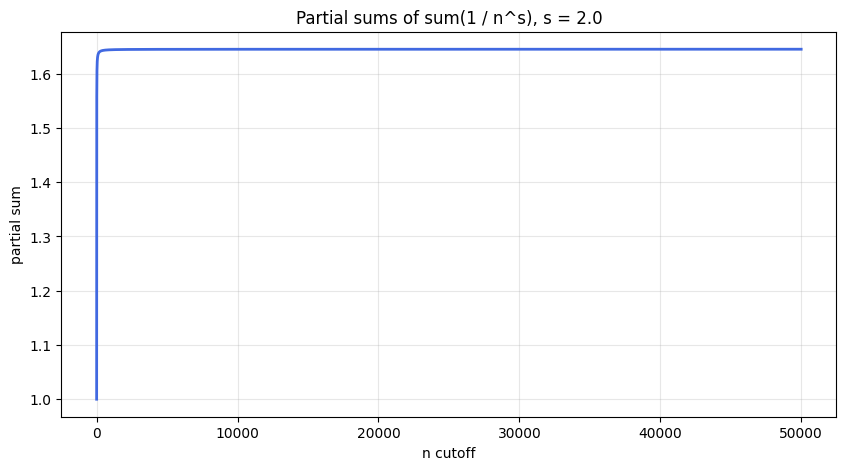

Last partial sum, n <= 50000: 1.64491406705


In [15]:
series_x, series_y = zeta_partial_sums(s, max_n)

plt.figure(figsize=(10, 5))
plt.plot(series_x, series_y, color="royalblue", linewidth=2)
plt.title(f"Partial sums of sum(1 / n^s), s = {s}")
plt.xlabel("n cutoff")
plt.ylabel("partial sum")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Last partial sum, n <= {max_n}: {series_y[-1]:.12g}")

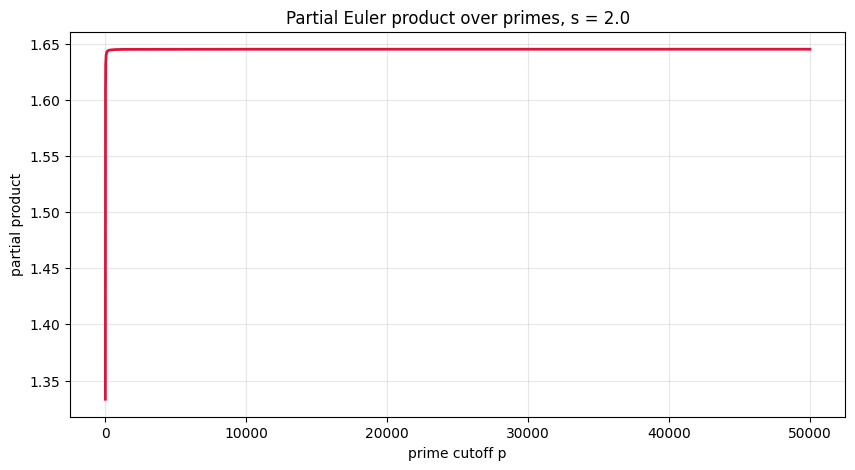

Last partial product, p <= 49999: 1.6449312703


In [16]:
prime_x, product_y = euler_partial_products(s, max_prime)

plt.figure(figsize=(10, 5))
plt.plot(prime_x, product_y, color="crimson", linewidth=2)
plt.title(f"Partial Euler product over primes, s = {s}")
plt.xlabel("prime cutoff p")
plt.ylabel("partial product")
plt.grid(True, alpha=0.3)
plt.show()

if product_y:
    print(f"Last partial product, p <= {prime_x[-1]}: {product_y[-1]:.12g}")
else:
    print("No primes found. Increase max_prime to at least 2.")

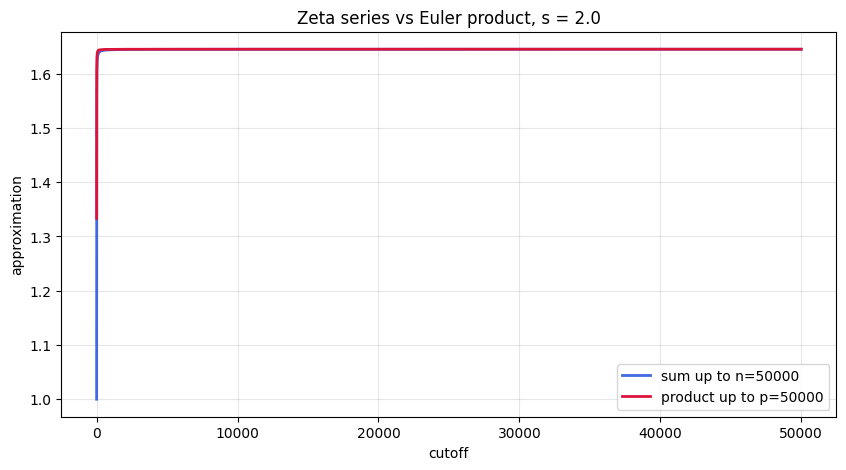

In [17]:
# Optional: compare both approximations on one matplotlib graph.
plt.figure(figsize=(10, 5))
plt.plot(series_x, series_y, label=f"sum up to n={max_n}", color="royalblue", linewidth=2)
plt.plot(prime_x, product_y, label=f"product up to p={max_prime}", color="crimson", linewidth=2)
plt.title(f"Zeta series vs Euler product, s = {s}")
plt.xlabel("cutoff")
plt.ylabel("approximation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

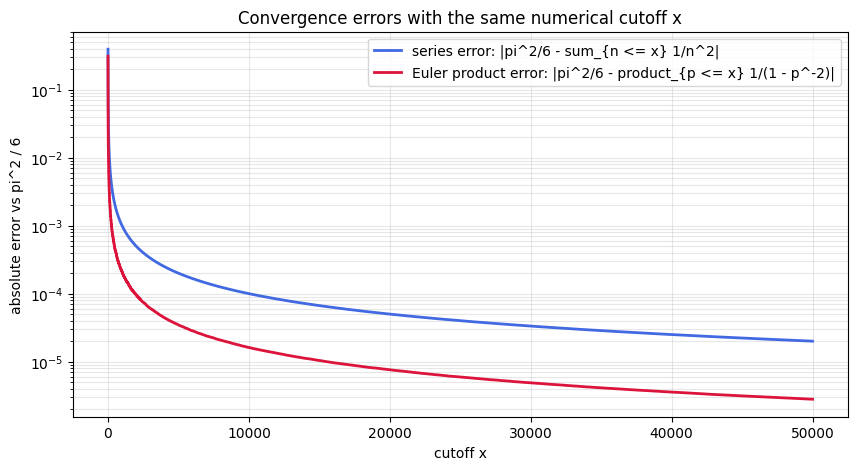

True value pi^2 / 6: 1.64493406685
Last series error, x = 50000: 1.99997999848e-05
Last Euler product error, x = 50000: 2.79654760371e-06


In [18]:
# Fair convergence comparison for s = 2.
# At each x, both approximations use the same numerical cutoff:
#   series:  sum over integers n <= x
#   product: product over primes p <= x
import math

if s != 2:
    print("This cell uses the exact value zeta(2) = pi^2 / 6. Set s = 2 for this comparison.")
else:
    true_value = math.pi**2 / 6
    x_values = list(range(2, min(max_n, max_prime) + 1))
    primes = primes_up_to(max(x_values))

    sum_errors = []
    product_errors = []
    running_sum = 0.0
    running_product = 1.0
    prime_index = 0

    for x in range(1, max(x_values) + 1):
        running_sum += 1 / (x**2)

        while prime_index < len(primes) and primes[prime_index] <= x:
            p = primes[prime_index]
            running_product *= 1 / (1 - p**-2)
            prime_index += 1

        if x >= 2:
            sum_errors.append(abs(true_value - running_sum))
            product_errors.append(abs(true_value - running_product))

    plt.figure(figsize=(10, 5))
    plt.plot(x_values, sum_errors, label="series error: |pi^2/6 - sum_{n <= x} 1/n^2|", color="royalblue", linewidth=2)
    plt.plot(x_values, product_errors, label="Euler product error: |pi^2/6 - product_{p <= x} 1/(1 - p^-2)|", color="crimson", linewidth=2)
    plt.yscale("log")
    plt.title("Convergence errors with the same numerical cutoff x")
    plt.xlabel("cutoff x")
    plt.ylabel("absolute error vs pi^2 / 6")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.show()

    print(f"True value pi^2 / 6: {true_value:.12g}")
    print(f"Last series error, x = {x_values[-1]}: {sum_errors[-1]:.12g}")
    print(f"Last Euler product error, x = {x_values[-1]}: {product_errors[-1]:.12g}")